# Anomalías: avisar de la avería sin gritar «¡que viene el lobo!»

**Avanzado · Jornada 2 · Bloque 2.4 · diapositivas contexto, mad, presupuesto, sembrar y ejercicio-detectores**

¿Cómo se detecta un cargador averiado en 40 bases sin inundar al centro de control? Comparamos con lo normal a esa hora, usamos mediana y MAD, fijamos un presupuesto de alarmas y cronometramos tres detectores con averías sembradas.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## 1. La pregunta

BiciCiudad tiene 40 bases de carga. Cuando un cargador se avería, la base pierde energía día y noche. Queremos
enterarnos cuanto antes **sin inundar al centro de control de alarmas**: cada falsa alarma resta credibilidad
a la siguiente, como en Pedro y el lobo.

> **Mensaje clave del bloque:** un detector se juzga por los días de avería ahorrados, no por su elegancia.

In [2]:
# Tres ayudas de formato en español.
import warnings

warnings.filterwarnings("ignore")  # avisos de convergencia y de versiones: no cambian los resultados


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"

In [3]:
from sklearn.ensemble import IsolationForest

ENE = DATOS / "energia_bases"

## 2. Cargar y mirar los datos

El consumo horario de las 40 bases (`kwh` son los kW medios de cada hora) y el resumen diario, con el
**mínimo nocturno**: el menor de los cuatro cuartos de hora entre las 3:00 y las 4:00, cuando casi no se
carga ninguna bici.

In [4]:
horario = pd.read_parquet(ENE / "horario.parquet")
horario["base_id"] = horario["base_id"].astype(str)
horario["local"] = bici.hora_local(horario["ts_utc"])
horario["dia"] = pd.to_datetime(horario["local"].dt.date)
horario["hora"] = horario["local"].dt.hour

diario = pd.read_csv(ENE / "diario.csv", parse_dates=["fecha"])
diario = diario.sort_values(["base_id", "fecha"]).reset_index(drop=True)
print(f"Horario: {n(len(horario))} filas. Diario: {n(len(diario))} filas, "
      f"del {fecha(diario['fecha'].min())} al {fecha(diario['fecha'].max())}")
diario.head(3)

Horario: 700.800 filas. Diario: 29.200 filas, del 1-10-2024 al 30-9-2026


,base_id,fecha,consumo_kwh,entregada_kwh,entregada_g1_kwh,entregada_g2_kwh,baterias_g1,baterias_g2,no_contabilizada_kwh,minimo_nocturno_kw
0,B-01,2024-10-01,3901.4,3240.6,2272.7,967.9,146,42,660.8,15.63
1,B-01,2024-10-02,3998.0,3334.1,2345.3,988.8,146,42,663.9,15.14
2,B-01,2024-10-03,4345.8,3646.3,2564.7,1081.6,146,42,699.5,15.81


## 3. Contexto: 91 kW a las 3:00 es una avería; a las 6:00, un martes cualquiera

La base B-09 el martes 18 de noviembre de 2025. Comparamos cada hora con **lo normal a esa hora**: la mediana
de esa misma hora en los laborables de las cuatro semanas anteriores, y medimos la distancia en MAD (la mediana
de las desviaciones absolutas, escalada × 1,4826 para que se lea como una desviación típica).

In [5]:
base, dia = "B-09", pd.Timestamp("2025-11-18")   # ← probad otra base o día
b = horario[horario["base_id"] == base]

antes = b[(b["dia"] < dia) & (b["dia"] >= dia - pd.Timedelta(days=28)) & (b["dia"].dt.dayofweek < 5)]
normal = antes.groupby("hora")["kwh"].median()
mad = antes.groupby("hora")["kwh"].apply(lambda x: 1.4826 * (x - x.median()).abs().median())
hoy = b[b["dia"] == dia].set_index("hora")["kwh"]

comparacion = pd.DataFrame({"consumo_kw": hoy, "normal_kw": normal, "distancia_en_MAD": (hoy - normal) / mad})
comparacion.loc[[3, 6]].round(1)

,consumo_kw,normal_kw,distancia_en_MAD
hora,,,
3,91.1,20.9,498.4
6,95.7,94.4,0.3


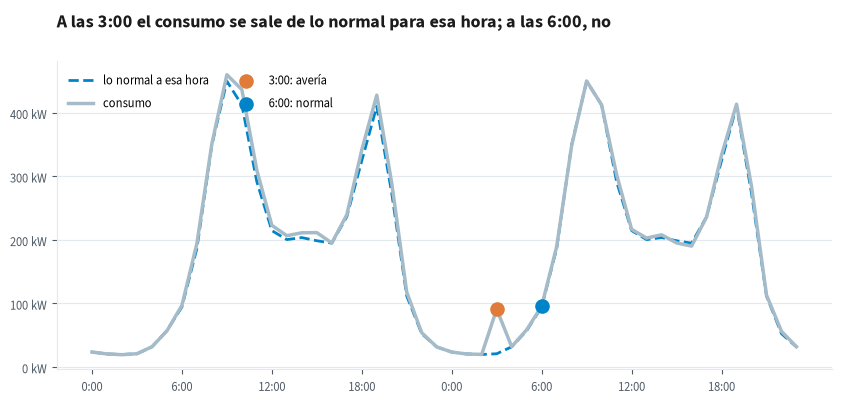

In [6]:
dos_dias = b[(b["dia"] >= dia - pd.Timedelta(days=1)) & (b["dia"] <= dia)].reset_index(drop=True)
x = np.arange(len(dos_dias))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, dos_dias["hora"].map(normal), color=estilo.AZUL, linestyle="--", label="lo normal a esa hora")
ax.plot(x, dos_dias["kwh"], color=estilo.GRIS, linewidth=2.5, label="consumo")
i3 = dos_dias.index[(dos_dias["dia"] == dia) & (dos_dias["hora"] == 3)][0]
i6 = dos_dias.index[(dos_dias["dia"] == dia) & (dos_dias["hora"] == 6)][0]
ax.scatter([i3], [dos_dias["kwh"][i3]], s=90, color=estilo.NARANJA, zorder=3, label="3:00: avería")
ax.scatter([i6], [dos_dias["kwh"][i6]], s=90, color=estilo.AZUL, zorder=3, label="6:00: normal")
ax.set_title("A las 3:00 el consumo se sale de lo normal para esa hora; a las 6:00, no")
ax.set_xticks(x[::6], [f"{h}:00" for h in dos_dias["hora"][::6]])
estilo.formato_eje(ax, sufijo=" kW")
ax.legend(loc="upper left", ncol=2)
plt.show()

Ningún umbral fijo separa la avería de la normalidad, porque la normalidad cambia con la hora. Por eso se
trabaja sobre **residuos**: lo que queda al quitar lo normal.

## 4. La mediana y la MAD no se dejan arrastrar por la avería

El mínimo nocturno de B-29 de septiembre a noviembre de 2025, menos su mediana. Comparamos los límites de la
media ± 3 desviaciones típicas con los de ± 3 MAD.

In [7]:
veces = 3   # ← anchura de los límites

s29 = diario[(diario["base_id"] == "B-29") & diario["fecha"].between("2025-09-01", "2025-11-30")]
s29 = s29.set_index("fecha")["minimo_nocturno_kw"]
residuo = s29 - s29.median()
sigma = residuo.std()
mad29 = 1.4826 * residuo.abs().median()

fuera_sigma = (residuo - residuo.mean()).abs() > veces * sigma
fuera_mad = residuo.abs() > veces * mad29
print(f"Desviación típica: {n(sigma, 2)} kW → límites de ±{n(veces * sigma, 1)} kW; días fuera: {fuera_sigma.sum()}")
print(f"MAD: {n(mad29, 2)} kW → límites de ±{n(veces * mad29, 1)} kW; días fuera: {fuera_mad.sum()}, "
      f"del {fecha(residuo.index[fuera_mad].min())} al {fecha(residuo.index[fuera_mad].max())}")

Desviación típica: 1,41 kW → límites de ±4,2 kW; días fuera: 0
MAD: 0,56 kW → límites de ±1,7 kW; días fuera: 28, del 20-10-2025 al 16-11-2025


La avería (unos 3 kW durante cuatro semanas) infla la desviación típica y se esconde detrás de sus propios
límites. La mediana y la MAD no se enteran, porque cuatro semanas son menos de la mitad de los datos.

## 5. Cinco alarmas al día como máximo, o nadie las mirará

Un detector que parece razonable: alarma si una base consume en una hora más de un 10 % por encima de la misma
hora de la semana anterior. En las 40 bases, durante cuatro semanas de noviembre de 2025:

In [8]:
subida = 0.10   # ← probad 0.15 y 0.20

h = horario.sort_values(["base_id", "ts_utc"]).copy()
h["semana_antes"] = h.groupby("base_id")["kwh"].shift(168)   # la misma hora, 168 horas antes
nov = h[h["dia"].between("2025-11-03", "2025-11-30")]
alarmas_dia = (nov["kwh"] > nov["semana_antes"] * (1 + subida)).groupby(nov["dia"]).sum()

print(f"Subida del {pct(subida, 0)}: {n(alarmas_dia.mean(), 1)} alarmas al día de media "
      f"(de {alarmas_dia.min()} a {alarmas_dia.max()}); {(alarmas_dia > 5).sum()} de {len(alarmas_dia)} días por encima de 5")

Subida del 10 %: 32,4 alarmas al día de media (de 3 a 64); 27 de 28 días por encima de 5


Cuarenta bases por veinticuatro horas son casi mil contrastes al día: con un umbral flojo, las falsas alarmas
están garantizadas. La solución es de gestión: decidir antes cuántas alarmas al día se pueden atender (aquí,
cinco) y elegir el detector que más detecta **dentro** de ese presupuesto.

## 6. Sin etiquetas, siembra averías y cronometra

Casi nunca hay una lista fiable de averías pasadas. La salida: coger datos reales, **inyectarles averías
inventadas** de fecha y forma conocidas, pasar los detectores y cronometrar cuántos días tardan en avisar.

Dos detectores clásicos sobre el mínimo nocturno, con la media y la sigma de los 90 días anteriores a la avería:
Shewhart (avisa cuando un día se pasa de 3 sigmas) y CUSUM (acumula lo que cada día se pasa de la media).

In [9]:
def limites(referencia):
    # Media y sigma del rango móvil (gráfico XmR)
    x = np.asarray(referencia, float)
    return x.mean(), np.abs(np.diff(x)).mean() / 1.128


def shewhart(x, media, sigma, L=3.0):
    fuera = np.flatnonzero(np.asarray(x) > media + L * sigma)
    return int(fuera[0]) if len(fuera) else None   # días hasta la primera alarma


def cusum(x, media, sigma, k=0.5, h=5.0):
    suma = 0.0
    for dia_i, valor in enumerate(x):
        suma = max(0.0, suma + (valor - media) / sigma - k)   # lo que se pasa, en sigmas, menos una holgura k
        if suma > h:
            return dia_i
    return None


minimo = diario.pivot(index="fecha", columns="base_id", values="minimo_nocturno_kw")

Sembramos una avería gradual (unos vatios más cada día) en cuatro bases que en la Jornada 1 vimos sanas.
Cambiad la pendiente y la fecha.

In [10]:
pendiente_w = 10                       # ← vatios más cada día
inicio = pd.Timestamp("2025-06-01")    # ← cuándo empieza
bases_sanas = ["B-05", "B-07", "B-14", "B-38"]

filas = []
for base_s in bases_sanas:
    serie = minimo[base_s].copy()                    # una copia: los datos no se tocan
    dias = (serie.index - inicio).days.to_numpy()
    serie = serie + np.where(dias >= 0, dias * pendiente_w / 1000, 0)   # la rampa, en kW
    media, sigma = limites(serie[:inicio - pd.Timedelta(days=1)].tail(90))
    tras = serie[inicio:].to_numpy()
    filas.append({"base": base_s, "Shewhart": shewhart(tras, media, sigma), "CUSUM": cusum(tras, media, sigma)})
pd.DataFrame(filas).set_index("base")

,Shewhart,CUSUM
base,,
B-05,32,18
B-07,17,25
B-14,67,25
B-38,38,30


Las averías lentas no producen ningún día extremo: hay que **acumular evidencia**. En los datos del curso ya hay
16 averías sembradas en las 40 bases (7 graduales, 7 escalones y 2 picos). Sobre las 7 graduales, un CUSUM
tarda de mediana 19 días en verlas y un Shewhart, 34. Es solo un adelanto: el CUSUM y el EWMA son el plato
fuerte de la Jornada 4.

## 7. Ejercicio (equipos, 30 min): tres detectores, 40 bases, cinco alarmas al día

Cada detector da una **puntuación** por base y día; se da la alarma cuando pasa de un umbral.

1. **Regla:** el mínimo nocturno en kW, con un umbral fijo igual para todas las bases.
2. **Robusto:** el residuo del mínimo nocturno frente a su mediana de los 28 días anteriores, medido en MAD.
3. **Isolation Forest:** sobre tres residuos diarios (mínimo nocturno, energía no contabilizada y consumo).

In [11]:
por_base = diario.groupby("base_id")


def residuo_28d(columna, relativo=False):
    # El valor de hoy menos la mediana de los 28 días anteriores de la misma base
    mediana = por_base[columna].transform(lambda x: x.shift(1).rolling(28, min_periods=14).median())
    r = diario[columna] - mediana
    return r / mediana if relativo else r


# 2. Robusto: residuo en kW, dividido por la MAD de los residuos de los 90 días anteriores
diario["residuo_kw"] = residuo_28d("minimo_nocturno_kw")
escala = diario.assign(a=diario["residuo_kw"].abs()).groupby("base_id")["a"].transform(
    lambda x: x.shift(1).rolling(90, min_periods=14).median())
diario["z_robusto"] = diario["residuo_kw"] / (1.4826 * escala)

# 3. Isolation Forest: tres residuos a la vez; cuanto más alta la puntuación, más rara la base ese día
variables_if = pd.DataFrame({"minimo": diario["residuo_kw"],
                             "no_contabilizada": residuo_28d("no_contabilizada_kwh", relativo=True),
                             "consumo": residuo_28d("consumo_kwh", relativo=True)}).fillna(0)
bosque = IsolationForest(n_estimators=200, random_state=2026).fit(variables_if)
diario["rareza_if"] = -bosque.score_samples(variables_if)

PUNTUACIONES = {"Regla": "minimo_nocturno_kw", "Robusto": "z_robusto", "Isolation Forest": "rareza_if"}
diario[["base_id", "fecha"] + list(PUNTUACIONES.values())].dropna().head()

,base_id,fecha,minimo_nocturno_kw,z_robusto,rareza_if
28,B-01,2024-10-29,15.25,-0.516277,0.467624
29,B-01,2024-10-30,15.41,0.057813,0.388469
30,B-01,2024-10-31,15.78,1.532934,0.464844
31,B-01,2024-11-01,15.03,-1.445337,0.493613
32,B-01,2024-11-02,15.09,-1.015900,0.548189


**Cómo se cuentan las alarmas.** Una alarma abierta no se repite: si una base sigue marcada al día siguiente,
el centro de control ya lo sabe. Cuenta el primer día de cada racha. El presupuesto: **ningún día más de 5**
en el conjunto de las 40 bases.

In [12]:
def alarmas_por_dia(marcada):
    ayer = marcada.groupby(diario["base_id"]).shift(1, fill_value=False)
    nuevas = marcada & ~ayer                       # solo el primer día de cada racha
    return nuevas.groupby(diario["fecha"]).sum()

Ajustad los tres umbrales: lo más sensibles posible sin que ningún día pase de 5 alarmas.

In [13]:
umbral_regla_kw = 21.0   # ← regla: mínimo nocturno por encima de estos kW
umbral_robusto = 3.0     # ← robusto: residuo por encima de estas veces la MAD
umbral_if = 0.60         # ← Isolation Forest: rareza por encima de este valor
umbrales = {"Regla": umbral_regla_kw, "Robusto": umbral_robusto, "Isolation Forest": umbral_if}

In [14]:
marcadas = {nombre: diario[col] >= umbrales[nombre] for nombre, col in PUNTUACIONES.items()}
for nombre, marcada in marcadas.items():
    a = alarmas_por_dia(marcada)
    print(f"{nombre:17s} umbral {n(umbrales[nombre], 2)}: {n(a.mean(), 2)} alarmas al día de media, "
          f"máximo {a.max()}; {(a > 5).sum()} días por encima de 5")

Regla             umbral 21,00: 0,92 alarmas al día de media, máximo 11; 1 días por encima de 5
Robusto           umbral 3,00: 0,05 alarmas al día de media, máximo 2; 0 días por encima de 5
Isolation Forest  umbral 0,60: 0,57 alarmas al día de media, máximo 16; 16 días por encima de 5


**Clave para puntuar.** Las 16 averías sembradas. No la miréis hasta haber ajustado los umbrales. Una avería
cuenta como vista si hay una alarma en su base entre su inicio y su final; las que no tienen final siguen al
cierre de los datos.

In [15]:
clave = pd.DataFrame([
    ("B-03", "gradual", "2024-10-21", "2025-06-10"), ("B-40", "gradual", "2025-04-01", "2026-01-12"),
    ("B-26", "gradual", "2025-05-12", None), ("B-19", "gradual", "2025-06-02", "2025-11-03"),
    ("B-28", "gradual", "2025-09-15", None), ("B-12", "gradual", "2025-12-01", None),
    ("B-35", "gradual", "2026-04-06", None),
    ("B-02", "escalón", "2024-11-04", "2024-12-02"), ("B-11", "escalón", "2025-04-14", "2025-05-05"),
    ("B-21", "escalón", "2025-07-07", "2025-10-06"), ("B-29", "escalón", "2025-10-20", "2025-11-17"),
    ("B-31", "escalón", "2026-01-19", None), ("B-33", "escalón", "2026-02-09", "2026-03-16"),
    ("B-37", "escalón", "2026-06-15", "2026-07-06"),
    ("B-09", "pico", "2025-11-18", "2025-11-18"), ("B-24", "pico", "2026-04-22", "2026-04-22"),
], columns=["base_id", "tipo", "inicio", "fin"])
clave["inicio"] = pd.to_datetime(clave["inicio"])
clave["fin"] = pd.to_datetime(clave["fin"]).fillna(diario["fecha"].max())


def puntuar(marcada):
    filas = []
    for a in clave.itertuples():
        en_averia = marcada & (diario["base_id"] == a.base_id) & diario["fecha"].between(a.inicio, a.fin)
        primera = diario.loc[en_averia, "fecha"].min()
        dias = (primera - a.inicio).days if pd.notna(primera) else np.nan
        duracion = (a.fin - a.inicio).days + 1
        filas.append({"base_id": a.base_id, "tipo": a.tipo, "dias_hasta_detectar": dias,
                      "dias_sin_ver": dias if pd.notna(dias) else duracion})
    return pd.DataFrame(filas)


detalle = {nombre: puntuar(marcada) for nombre, marcada in marcadas.items()}
resultado = pd.DataFrame({
    nombre: {"averías vistas (de 16)": d["dias_hasta_detectar"].notna().sum(),
             "días hasta detectar las graduales (mediana)": d.loc[d["tipo"] == "gradual", "dias_hasta_detectar"].median(),
             "días de avería sin ver (total)": d["dias_sin_ver"].sum(),
             "alarmas al día (media)": round(alarmas_por_dia(marcadas[nombre]).mean(), 2),
             "alarmas al día (máximo)": alarmas_por_dia(marcadas[nombre]).max()}
    for nombre, d in detalle.items()})
resultado

,Regla,Robusto,Isolation Forest
averías vistas (de 16),10.00,10.00,15.00
días hasta detectar las graduales (mediana),0.00,30.00,101.00
días de avería sin ver (total),1138.00,1694.00,742.00
alarmas al día (media),0.92,0.05,0.57
alarmas al día (máximo),11.00,2.00,16.00


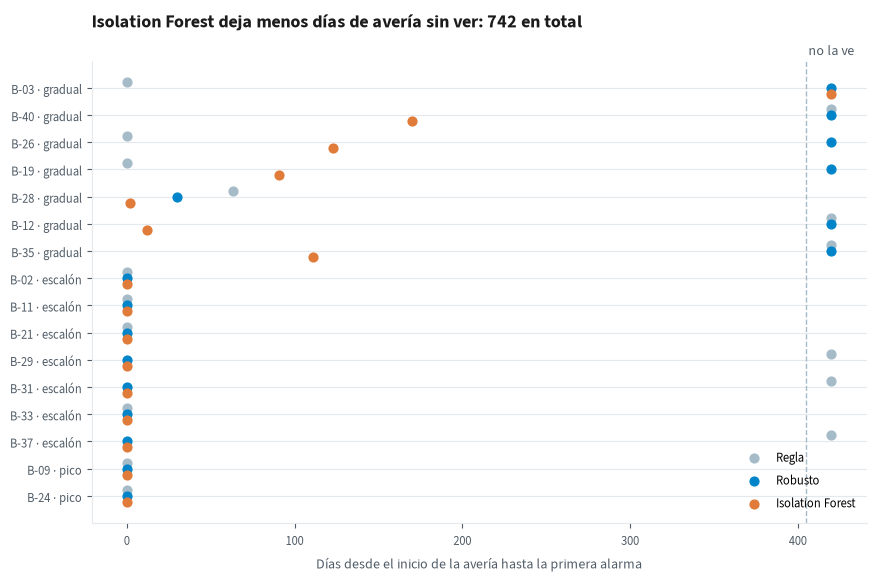

In [16]:
# Días hasta la primera alarma, avería a avería (a la derecha, las que no se ven)
tope = 420
fig, ax = plt.subplots(figsize=(10, 6))
etiquetas = [f"{a.base_id} · {a.tipo}" for a in clave.itertuples()]
for k, (nombre, color) in enumerate(zip(detalle, [estilo.GRIS, estilo.AZUL, estilo.NARANJA])):
    d = detalle[nombre]
    x = d["dias_hasta_detectar"].fillna(tope)
    ax.scatter(x, np.arange(len(d)) + (k - 1) * 0.22, s=40, color=color, label=nombre)
ax.axvline(tope - 15, color=estilo.GRIS, linewidth=1, linestyle="--")
ax.text(tope, -1.2, "no la ve", ha="center", color=estilo.TEXTO_2)
ax.set_yticks(np.arange(len(clave)), etiquetas)
ax.invert_yaxis()
ax.set_xlabel("Días desde el inicio de la avería hasta la primera alarma")
mejor = resultado.loc["días de avería sin ver (total)"].astype(float).idxmin()
ax.set_title(f"{mejor} deja menos días de avería sin ver: "
             f"{n(resultado.loc['días de avería sin ver (total)', mejor])} en total")
ax.legend(loc="lower right")
plt.show()

## Qué os lleváis

- Comparad con **lo normal a esa hora y ese día**, no con un umbral fijo: 91 kW a las 3:00 es una avería;
  96 kW a las 6:00, un martes cualquiera.
- **Mediana y MAD:** la avería no puede ensanchar los límites que la tienen que detectar.
- Un **presupuesto de alarmas** decidido antes, y el detector que más días ahorra dentro de ese presupuesto.
- Sin etiquetas, **sembrad averías y cronometrad**. Para lo lento, acumulad evidencia (Jornada 4).
- Un detector se juzga por los días de avería ahorrados, no por su elegancia.